# 06 - Reglas de Asociación

**Reglas de asociación con el algoritmo Apriori (soporte, confianza y lift).**

**Objetivo.** Descubrir combinaciones de características de navegación asociadas con la compra (`Revenue=compra`) o con el abandono (`Revenue=no_compra`), en forma de reglas *"si ocurre A, entonces suele ocurrir B"* fáciles de interpretar para el negocio.

**Entrada.** `data/datos_discretizados.csv`: las variables numéricas ya vienen discretizadas por terciles (el cero forma su propia categoría) y cada valor está escrito como `variable=valor`. Se usa la misma partición del equipo (80 % `train` / 20 % `test`, `random_state=42`).

## 1. Configuración

In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from collections import Counter
from itertools import combinations
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# Parámetros de la minería
RUTA = "data/datos_discretizados.csv"
MIN_SUPPORT = 0.01      # >= 1 % de las sesiones de entrenamiento (~98 sesiones)
MAX_LEN = 4             # itemsets de a lo más 4 ítems (reglas legibles y sin explosión combinatoria)
CONF_COMPRA = 0.30      # ~2 veces la tasa base de compra (15.6 %)
LIFT_COMPRA = 2.0
CONF_ABANDONO = 0.95
os.makedirs("figuras", exist_ok=True)

# Paleta: azul = compra, naranja = no compra, gris = neutro
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#9a9a95"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 110,
                     "axes.titlesize": 12, "axes.titleweight": "bold"})

## 2. Carga de datos y construcción de transacciones

In [ ]:
df = pd.read_csv(RUTA)
print("Forma del archivo:", df.shape)
df.head(3).T

Forma del archivo: (12205, 15)


,0,1,2
Administrative,Administrative=0,Administrative=0,Administrative=0
Informational,Informational=0,Informational=0,Informational=0
ProductRelated,ProductRelated=bajo,ProductRelated=bajo,ProductRelated=bajo
Administrative_Duration,Administrative_Duration=0,Administrative_Duration=0,Administrative_Duration=0
Informational_Duration,Informational_Duration=0,Informational_Duration=0,Informational_Duration=0
ProductRelated_Duration,ProductRelated_Duration=0,ProductRelated_Duration=bajo,ProductRelated_Duration=0
BounceRates,BounceRates=alto,BounceRates=0,BounceRates=alto
ExitRates,ExitRates=alto,ExitRates=alto,ExitRates=alto
PageValues,PageValues=0,PageValues=0,PageValues=0
SpecialDay,SpecialDay=lejos,SpecialDay=lejos,SpecialDay=lejos


In [ ]:
# Misma partición que el resto del equipo (80/20 estratificada, random_state=42)
train_df = df[df.conjunto == "train"].drop(columns="conjunto")
test_df  = df[df.conjunto == "test"].drop(columns="conjunto")

# Cada sesión es una transacción: lista de ítems "variable=valor"
transactions      = [fila.dropna().astype(str).tolist() for _, fila in train_df.iterrows()]
transactions_test = [fila.dropna().astype(str).tolist() for _, fila in test_df.iterrows()]
print(f"Transacciones de entrenamiento: {len(transactions)} | de prueba: {len(transactions_test)}")
transactions[:2]

Transacciones de entrenamiento: 9764 | de prueba: 2441


[['Administrative=0',
  'Informational=0',
  'ProductRelated=bajo',
  'Administrative_Duration=0',
  'Informational_Duration=0',
  'ProductRelated_Duration=0',
  'BounceRates=alto',
  'ExitRates=alto',
  'PageValues=0',
  'SpecialDay=lejos',
  'Month=Feb',
  'VisitorType=Returning_Visitor',
  'Weekend=no',
  'Revenue=no_compra'],
 ['Administrative=0',
  'Informational=0',
  'ProductRelated=bajo',
  'Administrative_Duration=0',
  'Informational_Duration=0',
  'ProductRelated_Duration=0',
  'BounceRates=alto',
  'ExitRates=alto',
  'PageValues=0',
  'SpecialDay=lejos',
  'Month=Feb',
  'VisitorType=Returning_Visitor',
  'Weekend=no',
  'Revenue=no_compra']]

## 3. Exploración de las transacciones

Ítems distintos: 55


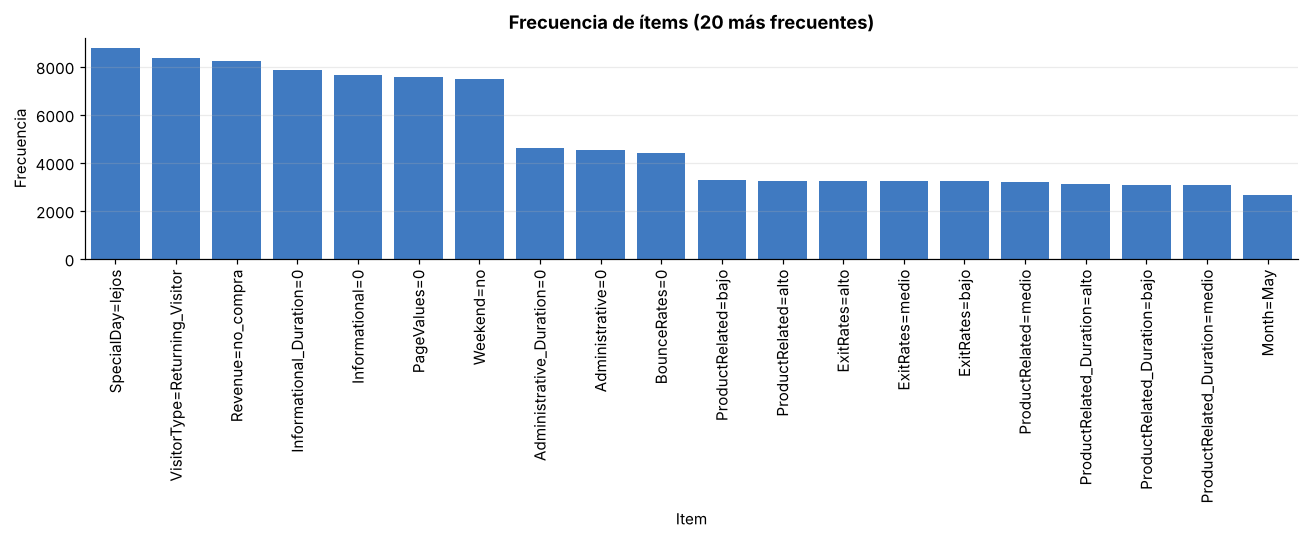

In [ ]:
# Frecuencia de cada ítem en las transacciones de entrenamiento (los 20 más frecuentes)
item_counts = Counter([item for t in transactions for item in t])
item_df = pd.DataFrame(item_counts.items(), columns=["Item", "Frecuencia"]).sort_values(by="Frecuencia", ascending=False)
print("Ítems distintos:", len(item_df))

plt.figure(figsize=(12, 5))
sns.barplot(x="Item", y="Frecuencia", data=item_df.head(20), color=AZUL)
plt.xticks(rotation=90); plt.title("Frecuencia de ítems (20 más frecuentes)")
plt.tight_layout(); plt.savefig("figuras/asoc_0_frecuencia_items.png", dpi=160, bbox_inches="tight"); plt.show()

In [ ]:
# Número de ítems por transacción
num_items_series = pd.Series([len(t) for t in transactions])
display(num_items_series.describe(percentiles=[.25, .5, .75, .9]))

count    9764.0
mean       14.0
std         0.0
min        14.0
25%        14.0
50%        14.0
75%        14.0
90%        14.0
max        14.0
dtype: float64

Hay 55 ítems distintos. Los más frecuentes (`SpecialDay=lejos`, `Returning_Visitor`, `no_compra`, `Informational=0`, `PageValues=0`) describen la sesión típica: sin compra, de un visitante recurrente y sin páginas informativas.
Todas las transacciones tienen exactamente 14 ítems (uno por variable), así que no tiene sentido hacer un diagrama de caja del número de ítems: no hay variación que analizar.

## 4. Transformación de los datos

Se codifican las transacciones con `TransactionEncoder`: una matriz booleana con una fila por sesión y una columna por ítem. El conjunto de prueba se codifica con el mismo codificador (mismas columnas).

In [ ]:
# Codificar las transacciones (matriz booleana: una columna por ítem)
encoder = TransactionEncoder()
transactions_encoded = pd.DataFrame(encoder.fit(transactions).transform(transactions), columns=encoder.columns_)
T_train = transactions_encoded
T_test = pd.DataFrame(encoder.transform(transactions_test), columns=encoder.columns_)
print("Forma de la matriz (train):", T_train.shape)
print(f"Soporte base  P(compra)    = {T_train['Revenue=compra'].mean():.3f} (train) | {T_test['Revenue=compra'].mean():.3f} (test)")
print(f"Soporte base  P(no_compra) = {T_train['Revenue=no_compra'].mean():.3f} (train)")
transactions_encoded.head(3)

Forma de la matriz (train): (9764, 55)
Soporte base  P(compra)    = 0.156 (train) | 0.156 (test)
Soporte base  P(no_compra) = 0.844 (train)


,Administrative=0,Administrative=alto,Administrative=bajo,Administrative=medio,Administrative_Duration=0,Administrative_Duration=alto,Administrative_Duration=bajo,Administrative_Duration=medio,BounceRates=0,BounceRates=alto,...,ProductRelated_Duration=medio,Revenue=compra,Revenue=no_compra,SpecialDay=cerca,SpecialDay=lejos,VisitorType=New_Visitor,VisitorType=Other,VisitorType=Returning_Visitor,Weekend=no,Weekend=si
0,True,False,False,False,True,False,False,False,False,True,...,False,False,True,False,True,False,False,True,True,False
1,True,False,False,False,True,False,False,False,False,True,...,False,False,True,False,True,False,False,True,True,False
2,True,False,False,False,True,False,False,False,False,True,...,False,False,True,False,True,False,False,True,True,False


In [ ]:
# Porcentaje de transacciones en las que aparece cada ítem (los 15 más frecuentes)
sop_items = T_train.mean(axis=0).sort_values(ascending=False)
sop_items.head(15).round(3).to_frame("soporte")

,soporte
SpecialDay=lejos,0.897
VisitorType=Returning_Visitor,0.855
Revenue=no_compra,0.844
Informational_Duration=0,0.804
Informational=0,0.784
PageValues=0,0.776
Weekend=no,0.766
Administrative_Duration=0,0.474
Administrative=0,0.463
BounceRates=0,0.453


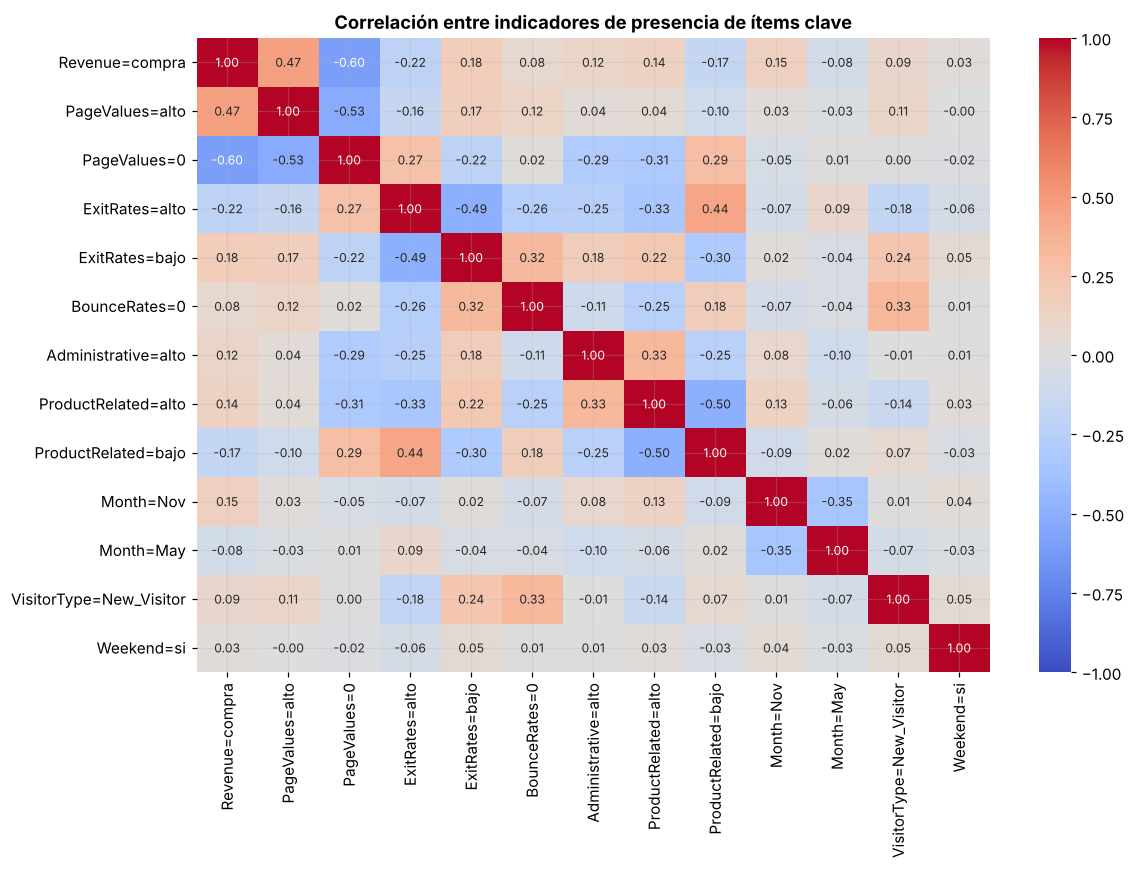

In [ ]:
# La correlación de Pearson entre indicadores binarios es exploratoria;
# no equivale a soporte, confianza ni lift de una regla.
CLAVE = ["Revenue=compra", "PageValues=alto", "PageValues=0", "ExitRates=alto", "ExitRates=bajo", "BounceRates=0",
         "Administrative=alto", "ProductRelated=alto", "ProductRelated=bajo", "Month=Nov", "Month=May",
         "VisitorType=New_Visitor", "Weekend=si"]
corr = transactions_encoded[CLAVE].astype(int).corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre indicadores de presencia de ítems clave")
plt.tight_layout(); plt.savefig("figuras/asoc_5_correlacion.png", dpi=160, bbox_inches="tight"); plt.show()

La correlación entre indicadores es solo exploratoria (no equivale a soporte, confianza ni lift). Con `Revenue=compra`, la correlación más fuerte es positiva con `PageValues=alto` (0.47) y negativa con `PageValues=0` (−0.60); después siguen `ExitRates=alto` (−0.22), `ExitRates=bajo` (0.18), `ProductRelated=bajo` (−0.17), `Month=Nov` (0.15) y `ProductRelated=alto` (0.14). `Weekend=si` casi no se relaciona (0.03). Las correlaciones negativas entre `ExitRates=alto` y `ExitRates=bajo` (−0.49) o entre `ProductRelated=alto` y `bajo` (−0.50) son esperadas: son categorías de la misma variable y no pueden ocurrir a la vez en una sesión.

## 5. Elección de parámetros

Apriori necesita un **soporte mínimo** y una **longitud máxima** de itemset. Además se toman dos decisiones de diseño:

- **Familias repetidas.** `ProductRelated` y `ProductRelated_Duration` (igual con `Administrative` e `Informational`) miden casi lo mismo, pues más páginas implican más tiempo. Se descartan los itemsets que mezclan conteo y duración de la misma sección, porque generan reglas triviales (por ejemplo `Administrative=0 → Administrative_Duration=0`, con confianza de 100 %).
- **Mejora mínima.** Una regla de varios ítems se conserva solo si su confianza supera en al menos 0.02 a la de cualquiera de sus sub-reglas; así se evitan reglas largas que solo repiten una más corta.

In [ ]:
def familia(item):
    """'ProductRelated_Duration=alto' y 'ProductRelated=alto' son la misma familia (conteo y duración)."""
    return item.split("=")[0].replace("_Duration", "")

def sin_familias_repetidas(itemset):
    fam = [familia(i) for i in itemset]
    return len(fam) == len(set(fam))

def txt(s):
    return " + ".join(sorted(s))

def minar(T, columnas_excluir=(), min_support=MIN_SUPPORT, max_len=MAX_LEN):
    """Apriori + reglas. Descarta itemsets que repiten la misma familia (conteo y duración de la misma
    sección), porque producen reglas triviales del tipo 'Administrative=0 -> Administrative_Duration=0'."""
    cols = [c for c in T.columns if not any(c.startswith(e) for e in columnas_excluir)]
    fi = apriori(T[cols], min_support=min_support, use_colnames=True, max_len=max_len, low_memory=True)
    fi = fi[fi.itemsets.map(sin_familias_repetidas)].reset_index(drop=True)
    reglas = association_rules(fi, metric="confidence", min_threshold=0.0)
    soporte = dict(zip(fi.itemsets, fi.support))
    return fi, reglas, soporte

def mejora(reglas, soporte):
    """Improvement (Bayardo): confianza de la regla menos la mayor confianza de cualquier sub-regla con el
    mismo consecuente. Si es ~0 el ítem extra del antecedente no aporta nada."""
    out = []
    for A, C_, conf in zip(reglas.antecedents, reglas.consequents, reglas.confidence):
        if len(A) == 1:
            out.append(np.nan); continue
        mejores = 0.0
        for k in range(1, len(A)):
            for sub in combinations(A, k):
                sub = frozenset(sub)
                if sub in soporte and (sub | C_) in soporte:
                    mejores = max(mejores, soporte[sub | C_] / soporte[sub])
        out.append(conf - mejores)
    return np.array(out)

def metricas_en(T, A, C_):
    """Soporte, confianza y lift de la regla A -> C medidos directamente sobre una matriz de transacciones."""
    ma = T[list(A)].all(axis=1); mc = T[list(C_)].all(axis=1)
    sop = (ma & mc).mean(); sa = ma.mean(); sc = mc.mean()
    conf = sop / sa if sa > 0 else np.nan
    return sop, conf, (conf / sc if sc > 0 else np.nan), int((ma & mc).sum())

In [ ]:
# Sensibilidad al soporte mínimo (todas las variables, max_len = 4)
filas = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01]:
    t0 = time.time()
    fi_s = apriori(T_train, min_support=ms, use_colnames=True, max_len=MAX_LEN, low_memory=True)
    fi_s = fi_s[fi_s.itemsets.map(sin_familias_repetidas)]
    rr = association_rules(fi_s, metric="confidence", min_threshold=0.30)
    a_compra = rr[rr.consequents.map(lambda s: s == frozenset({"Revenue=compra"}))]
    filas.append({"min_support": ms, "itemsets frecuentes": len(fi_s), "reglas (conf >= 0.30)": len(rr),
                  "reglas -> compra": len(a_compra), "segundos": round(time.time() - t0, 2)})
sens = pd.DataFrame(filas); sens

,min_support,itemsets frecuentes,reglas (conf >= 0.30),reglas -> compra,segundos
0,0.10,2154,14407,0,0.23
1,0.05,5186,29372,2,0.65
2,0.03,9421,46677,36,0.73
3,0.02,13404,60824,110,0.95
4,0.01,23389,91018,384,1.72


 Con soporte mínimo de 0.10 o 0.05 casi no hay reglas hacia `compra` (0 y 2), porque la compra aparece solo en el 15.6 % de las sesiones y un soporte alto exige que cubra una gran parte de ellas. Con 0.03 aparecen 36, con 0.02 hay 110 y con 0.01 hay 384, con un tiempo de cómputo de solo 1.5 s. Se elige **`MIN_SUPPORT = 0.01`** (≈ 98 sesiones de entrenamiento, suficiente para que una regla no sea anecdótica) y **`MAX_LEN = 4`** (sin tope de longitud el número de itemsets crece de forma explosiva y las reglas dejan de ser legibles).

## 6. Itemsets frecuentes (Apriori)

**Escenario A: todas las variables.**

In [ ]:
# Escenario A: todas las variables
fi_A, reglas_A, sop_A = minar(T_train)
reglas_A["mejora"] = mejora(reglas_A, sop_A)
print(f"[A] itemsets frecuentes: {len(fi_A)} | reglas candidatas: {len(reglas_A)}")
print(fi_A.assign(tamano=fi_A.itemsets.map(len)).groupby("tamano").size().rename("itemsets por tamaño").to_frame().T)

[A] itemsets frecuentes: 23389 | reglas candidatas: 270650
tamano                1    2     3      4
itemsets por tamaño  52  905  5651  16781


In [ ]:
top_fi = fi_A[fi_A.itemsets.map(len) >= 3].sort_values("support", ascending=False).head(10)
top_fi.assign(itemset=top_fi.itemsets.map(txt))[["itemset", "support"]].reset_index(drop=True)

,itemset,support
0,PageValues=0 + Revenue=no_compra + SpecialDay=lejos,0.656800
1,Revenue=no_compra + SpecialDay=lejos + VisitorType=Returning_Visitor,0.639799
2,PageValues=0 + Revenue=no_compra + VisitorType=Returning_Visitor,0.639697
3,Informational_Duration=0 + PageValues=0 + Revenue=no_compra,0.639594
4,Informational=0 + PageValues=0 + Revenue=no_compra,0.626690
5,Informational_Duration=0 + Revenue=no_compra + SpecialDay=lejos,0.606616
6,Informational_Duration=0 + Revenue=no_compra + VisitorType=Returning_Visitor,0.598628
7,Informational_Duration=0 + SpecialDay=lejos + VisitorType=Returning_Visitor,0.593302
8,Informational=0 + Revenue=no_compra + SpecialDay=lejos,0.592995
9,Informational=0 + Revenue=no_compra + VisitorType=Returning_Visitor,0.584699


Los itemsets más frecuentes de tres ítems combinan `no_compra`, `PageValues=0`, `SpecialDay=lejos` y `Returning_Visitor`: la sesión "normal" que termina sin compra (hasta 65.7 % de las sesiones). La mayoría de los itemsets frecuentes tiene 3 o 4 ítems (16,781 de 4 ítems), lo que confirma la necesidad de filtrar por lift y mejora para quedarse con lo interesante.

In [ ]:
# Itemsets frecuentes que contienen Revenue=compra (de 2 o más ítems), por soporte
fi_A[fi_A.itemsets.map(lambda x: "Revenue=compra" in x and len(x) >= 2)] \
    .sort_values("support", ascending=False).head(10).assign(itemset=lambda d: d.itemsets.map(txt))[["itemset", "support"]].reset_index(drop=True)

,itemset,support
0,Revenue=compra + SpecialDay=lejos,0.150041
1,Revenue=compra + VisitorType=Returning_Visitor,0.121364
2,Revenue=compra + SpecialDay=lejos + VisitorType=Returning_Visitor,0.116141
3,Revenue=compra + Weekend=no,0.115424
4,Informational_Duration=0 + Revenue=compra,0.111635
5,Revenue=compra + SpecialDay=lejos + Weekend=no,0.109689
6,Informational=0 + Revenue=compra,0.107538
7,Informational_Duration=0 + Revenue=compra + SpecialDay=lejos,0.107333
8,Informational=0 + Revenue=compra + SpecialDay=lejos,0.103646
9,Revenue=compra + VisitorType=Returning_Visitor + Weekend=no,0.089103


In [ ]:
# Itemsets que contienen a la vez Month=Nov y Revenue=compra
buscado = {"Month=Nov", "Revenue=compra"}
fi_A[fi_A.itemsets.map(lambda x: set(x).issuperset(buscado))] \
    .sort_values("support", ascending=False).head(8).assign(itemset=lambda d: d.itemsets.map(txt))[["itemset", "support"]].reset_index(drop=True)

,itemset,support
0,Month=Nov + Revenue=compra,0.061348
1,Month=Nov + Revenue=compra + SpecialDay=lejos,0.061348
2,Month=Nov + Revenue=compra + VisitorType=Returning_Visitor,0.050696
3,Month=Nov + Revenue=compra + SpecialDay=lejos + VisitorType=Returning_Visitor,0.050696
4,Month=Nov + Revenue=compra + Weekend=no,0.044654
5,Month=Nov + Revenue=compra + SpecialDay=lejos + Weekend=no,0.044654
6,Informational_Duration=0 + Month=Nov + Revenue=compra + SpecialDay=lejos,0.041172
7,Informational_Duration=0 + Month=Nov + Revenue=compra,0.041172


Los itemsets frecuentes que contienen `Revenue=compra` están dominados por ítems muy comunes (`SpecialDay=lejos`, `Returning_Visitor`, `Weekend=no`): por ejemplo `compra + SpecialDay=lejos` tiene soporte 15 %, casi igual al soporte de `compra` (15.6 %), porque `SpecialDay=lejos` aparece en casi todas las sesiones. Es decir, **un soporte alto no indica asociación**; por eso hace falta el lift. En cambio, `Month=Nov + Revenue=compra` tiene soporte 6.1 % y sí resulta informativo, como se verá en las reglas.

**Escenario B: sin `PageValues`.**

`PageValues` es el promedio del valor de las páginas visitadas *antes de completar una transacción*; es decir, se calcula en parte a partir de las propias compras. Es muy informativa pero casi circular para explicar la compra, y en una aplicación real no estaría disponible antes de que termine la sesión. Por eso se repite el análisis sin ella para encontrar patrones basados en el comportamiento de navegación y el contexto.

In [ ]:
# Escenario B: sin PageValues
fi_B, reglas_B, sop_B = minar(T_train, columnas_excluir=("PageValues",))
reglas_B["mejora"] = mejora(reglas_B, sop_B)
print(f"[B] itemsets frecuentes: {len(fi_B)} | reglas candidatas: {len(reglas_B)}")

[B] itemsets frecuentes: 17493 | reglas candidatas: 199446


## 7. Reglas hacia la compra (`Revenue=compra`)

**Criterios de selección.** Confianza ≥ 0.30 (casi el doble de la tasa base de 0.156), lift ≥ 2 y mejora ≥ 0.02. Se ordenan por lift y, a igualdad, por soporte.

In [ ]:
def seleccionar(reglas, consecuente, min_conf, min_lift, min_mejora=0.02, top=None):
    m = reglas.consequents.map(lambda s: s == frozenset({consecuente}))
    r = reglas[m & (reglas.confidence >= min_conf) & (reglas.lift >= min_lift)].copy()
    r = r[r.mejora.isna() | (r.mejora >= min_mejora)]           # quita extensiones redundantes
    r = r.sort_values(["lift", "support"], ascending=False)
    r["regla"] = r.antecedents.map(txt)
    cols = ["regla", "support", "confidence", "lift", "leverage", "conviction", "mejora"]
    r = r[["antecedents", "consequents"] + cols[1:] + ["regla"]]
    return r.head(top) if top else r

compra_A = seleccionar(reglas_A, "Revenue=compra", CONF_COMPRA, LIFT_COMPRA)
compra_B = seleccionar(reglas_B, "Revenue=compra", CONF_COMPRA, LIFT_COMPRA)
print("Reglas hacia compra  -> A:", len(compra_A), "| B:", len(compra_B))

mostrar = ["regla", "support", "confidence", "lift", "leverage", "mejora"]

Reglas hacia compra  -> A: 98 | B: 35


In [ ]:
compra_A.head(12)[mostrar].round(3).reset_index(drop=True)

,regla,support,confidence,lift,leverage,mejora
0,Administrative=0 + BounceRates=0 + PageValues=alto,0.016,0.976,6.242,0.014,0.064
1,Administrative_Duration=0 + BounceRates=0 + PageValues=alto,0.017,0.971,6.211,0.014,0.060
2,Administrative_Duration=0 + ExitRates=bajo + PageValues=alto,0.010,0.953,6.099,0.009,0.042
3,Administrative=0 + ExitRates=bajo + PageValues=alto,0.010,0.952,6.094,0.009,0.041
4,PageValues=alto + ProductRelated_Duration=medio + VisitorType=New_Visitor,0.011,0.945,6.046,0.009,0.058
5,BounceRates=0 + PageValues=alto + ProductRelated=bajo,0.010,0.927,5.929,0.009,0.033
6,Informational_Duration=0 + PageValues=alto + VisitorType=New_Visitor,0.016,0.918,5.871,0.013,0.030
7,Informational=0 + PageValues=alto + VisitorType=New_Visitor,0.016,0.917,5.868,0.013,0.030
8,Administrative=0 + PageValues=alto,0.019,0.912,5.834,0.016,0.157
9,Administrative_Duration=0 + PageValues=alto,0.020,0.911,5.828,0.016,0.156


**(Escenario A).** Dominan las reglas que contienen `PageValues=alto`: por sí sola da confianza 75.5 % y lift 4.83 (se ve en la sección 11), y combinada con otros ítems llega a confianza 90-98 % y lift ≈ 6. Por ejemplo, `Administrative=0 + BounceRates=0 + PageValues=alto` tiene confianza 97.6 %, lift 6.24 y soporte 1.6 %: casi todas las sesiones que van directo a producto, sin pasar por páginas administrativas, sin rebote y con páginas de alto valor, terminan en compra. También aparece `New_Visitor` con `PageValues=alto` (confianza ≈ 89 % con solo esos dos ítems), lo que indica que los visitantes nuevos que llegan a páginas de alto valor compran casi siempre. Las reglas con `Administrative=0` y `Administrative_Duration=0` son prácticamente la misma (toda sesión con `Administrative=0` también tiene `Administrative_Duration=0`).

In [ ]:
compra_B.head(15)[mostrar].round(3).reset_index(drop=True)

,regla,support,confidence,lift,leverage,mejora
0,Administrative=alto + ExitRates=bajo + Month=Nov,0.013,0.483,3.093,0.009,0.071
1,Administrative=alto + BounceRates=bajo + Month=Nov,0.012,0.476,3.044,0.008,0.063
2,Administrative_Duration=alto + ExitRates=bajo + Month=Nov,0.011,0.473,3.028,0.007,0.090
3,Administrative=alto + Month=Nov + ProductRelated=alto,0.019,0.459,2.936,0.013,0.047
4,Administrative=alto + Month=Nov + ProductRelated_Duration=alto,0.019,0.459,2.935,0.012,0.046
5,BounceRates=bajo + ExitRates=bajo + Month=Nov,0.013,0.457,2.927,0.009,0.075
6,ExitRates=bajo + Month=Nov + ProductRelated_Duration=alto,0.021,0.454,2.906,0.014,0.072
7,ExitRates=bajo + Month=Nov + ProductRelated=alto,0.022,0.446,2.854,0.015,0.064
8,Administrative_Duration=alto + Month=Nov + ProductRelated=alto,0.015,0.442,2.831,0.010,0.059
9,Administrative_Duration=alto + Month=Nov + ProductRelated_Duration=alto,0.015,0.434,2.778,0.010,0.051


**(Escenario B, sin `PageValues`).** Aparece un patrón distinto y más accionable: **noviembre combinado con alto compromiso de navegación**. La mejor regla, `Administrative=alto + ExitRates=bajo + Month=Nov`, tiene confianza 48.3 % y lift 3.09: en esas sesiones se compra tres veces más que en el promedio. Se repiten tres ingredientes: `Month=Nov`, tasas de salida o rebote bajas (el usuario sigue navegando) y mucha navegación (`Administrative=alto`, `ProductRelated=alto`). Incluso la regla más sencilla de la lista, `Administrative=alto + Month=Nov`, alcanza 41.2 % (lift 2.64) con soporte de 2.3 %. Aquí la confianza máxima ronda 48 %, mucho menor que en A, porque sin `PageValues` no hay un indicador casi determinista de compra.

## 8. Análisis detallado de dos reglas

In [ ]:
def detalle_regla(reglas, antecedente, consecuente):
    """Tabla con todas las métricas de una regla"""
    r = reglas[(reglas.antecedents == frozenset(antecedente)) & (reglas.consequents == frozenset(consecuente))].iloc[0]
    return pd.DataFrame({
        "Métrica": ["Soporte del antecedente", "Soporte del consecuente", "Soporte", "Confianza", "Lift", "Leverage", "Conviction"],
        "Valor": [r["antecedent support"], r["consequent support"], r.support, r.confidence, r.lift, r.leverage, r.conviction]
    }).round(4)

print("Regla A:  Administrative=0 + BounceRates=0 + PageValues=alto -> compra")
display(detalle_regla(reglas_A, {"Administrative=0", "BounceRates=0", "PageValues=alto"}, {"Revenue=compra"}))
print("Regla B:  Administrative=alto + ExitRates=bajo + Month=Nov -> compra")
display(detalle_regla(reglas_B, {"Administrative=alto", "ExitRates=bajo", "Month=Nov"}, {"Revenue=compra"}))

Regla A:  Administrative=0 + BounceRates=0 + PageValues=alto -> compra


,Métrica,Valor
0,Soporte del antecedente,0.0168
1,Soporte del consecuente,0.1563
2,Soporte,0.0164
3,Confianza,0.9756
4,Lift,6.2424
5,Leverage,0.0138
6,Conviction,34.5922


Regla B:  Administrative=alto + ExitRates=bajo + Month=Nov -> compra


,Métrica,Valor
0,Soporte del antecedente,0.0278
1,Soporte del consecuente,0.1563
2,Soporte,0.0134
3,Confianza,0.4834
4,Lift,3.0930
5,Leverage,0.0091
6,Conviction,1.6332


| Métrica | Regla A: `Administrative=0 + BounceRates=0 + PageValues=alto → compra` | Regla B: `Administrative=alto + ExitRates=bajo + Month=Nov → compra` |
|---|---:|---:|
| Soporte del antecedente | 1.68 % | 2.78 % |
| Soporte del consecuente | 15.63 % | 15.63 % |
| Soporte | 1.64 % | 1.34 % |
| Confianza | 97.56 % | 48.34 % |
| Lift | 6.24 | 3.09 |
| Leverage | 0.0138 | 0.0091 |
| Conviction | 34.59 | 1.63 |

**Interpretación.**
- **Regla A.** El 1.68 % de las sesiones cumple el antecedente, y casi todas (97.6 %) terminan en compra, frente a una tasa general de 15.6 %. El lift de 6.24 indica que comprar es 6 veces más probable en esas sesiones. Aquí la confianza alta **sí** es una asociación fuerte, porque el consecuente es poco frecuente. La conviction de 34.6 es muy alta: la regla casi nunca falla. Su leverage es pequeño (0.014) porque la regla cubre pocas sesiones; mide la diferencia entre el soporte observado y el esperado si fueran independientes.
- **Regla B.** La confianza es 48.3 % (menos de la mitad de las sesiones compra), pero el lift de 3.09 muestra que es 3 veces más probable que en general. La conviction de 1.63 es moderada: la regla falla con frecuencia, pero reduce de forma clara el riesgo de no compra. Es una asociación útil, aunque no una garantía.
- Ninguna de las dos reglas implica causalidad; describen las sesiones analizadas.

## 9. Reglas hacia el abandono (`Revenue=no_compra`)

Como el 84.4 % de las sesiones no compra, el lift máximo posible es 1 / 0.844 = **1.185**, así que los lifts hacia `no_compra` siempre serán modestos. Se piden confianza ≥ 0.95 y lift ≥ 1.10, y se ordenan por **soporte** (cuántas sesiones explican).

In [ ]:
# Abandono (Revenue=no_compra). Como la tasa base es 84 %, el lift máximo posible es 1/0.844 = 1.185
ab_A = seleccionar(reglas_A, "Revenue=no_compra", CONF_ABANDONO, 1.10, min_mejora=0.0)
ab_B = seleccionar(reglas_B, "Revenue=no_compra", CONF_ABANDONO, 1.10, min_mejora=0.0)
print("Reglas hacia no_compra -> A:", len(ab_A), "| B:", len(ab_B))
print("\nTop por soporte (A):")
ab_A.sort_values("support", ascending=False).head(8)[mostrar].round(3).reset_index(drop=True)

Reglas hacia no_compra -> A: 496 | B: 282

Top por soporte (A):


,regla,support,confidence,lift,leverage,mejora
0,PageValues=0,0.745,0.961,1.139,0.091,NaN
1,PageValues=0 + VisitorType=Returning_Visitor,0.640,0.965,1.144,0.080,0.004
2,Informational_Duration=0 + PageValues=0,0.640,0.966,1.145,0.081,0.005
3,Informational=0 + PageValues=0,0.627,0.967,1.146,0.080,0.007
4,PageValues=0 + Weekend=no,0.576,0.963,1.141,0.071,0.002
5,Informational_Duration=0 + PageValues=0 + VisitorType=Returning_Visitor,0.549,0.971,1.151,0.072,0.005
6,Informational=0 + PageValues=0 + VisitorType=Returning_Visitor,0.537,0.973,1.153,0.071,0.005
7,Informational_Duration=0 + PageValues=0 + Weekend=no,0.500,0.969,1.148,0.065,0.003


In [ ]:
print("Top por soporte (B, sin PageValues):")
ab_B.sort_values("support", ascending=False).head(8)[mostrar].round(3).reset_index(drop=True)

Top por soporte (B, sin PageValues):


,regla,support,confidence,lift,leverage,mejora
0,ExitRates=alto,0.317,0.955,1.131,0.037,NaN
1,ExitRates=alto + VisitorType=Returning_Visitor,0.299,0.957,1.134,0.035,0.002
2,ExitRates=alto + Informational_Duration=0,0.292,0.958,1.135,0.035,0.003
3,ExitRates=alto + Informational=0,0.286,0.959,1.137,0.034,0.005
4,ExitRates=alto + Informational_Duration=0 + VisitorType=Returning_Visitor,0.274,0.961,1.139,0.033,0.003
5,ExitRates=alto + Informational=0 + VisitorType=Returning_Visitor,0.269,0.962,1.140,0.033,0.003
6,ExitRates=alto + Weekend=no,0.255,0.957,1.134,0.030,0.002
7,Informational_Duration=0 + ProductRelated=bajo + VisitorType=Returning_Visitor,0.247,0.950,1.126,0.028,0.002


Con todas las variables, `PageValues=0 → no_compra` cubre el 74.5 % de las sesiones con confianza 96.1 % (lift 1.14): si las páginas visitadas nunca estuvieron asociadas a una transacción, casi nunca hay compra. Sin `PageValues`, la señal más fuerte es **`ExitRates=alto → no_compra`** (soporte 31.7 %, confianza 95.5 %): cuando las páginas visitadas son típicamente las últimas de otras sesiones, la sesión termina sin compra. Agregar `Returning_Visitor`, `Informational=0` o `Weekend=no` casi no cambia la confianza (mejora ≤ 0.007), así que esos ítems no explican el abandono; solo acompañan a la sesión más común. Este grupo de reglas es útil para *descartar* sesiones, pero ofrece menos novedad que las reglas hacia la compra.

## 10. Efecto individual de cada ítem

Las reglas de un solo ítem `{ítem} → compra` muestran qué características por separado favorecen o desfavorecen la compra (la tasa base es 15.6 %).

In [ ]:
# Efecto individual de cada ítem sobre la compra: regla {ítem} -> compra
s = reglas_A[(reglas_A.antecedents.map(len) == 1) & reglas_A.consequents.map(lambda x: x == frozenset({"Revenue=compra"}))].copy()
s["item"] = s.antecedents.map(txt)
s = s.sort_values("lift", ascending=False)
s[["item", "support", "confidence", "lift"]].round(3).reset_index(drop=True).head(12)

,item,support,confidence,lift
0,PageValues=alto,0.056,0.755,4.832
1,PageValues=medio,0.041,0.559,3.576
2,PageValues=bajo,0.029,0.377,2.414
3,Informational_Duration=alto,0.017,0.268,1.717
4,Informational=alto,0.018,0.255,1.630
5,Month=Nov,0.061,0.254,1.625
6,ExitRates=bajo,0.083,0.251,1.607
7,Administrative=alto,0.044,0.247,1.583
8,VisitorType=New_Visitor,0.033,0.241,1.542
9,ProductRelated_Duration=alto,0.075,0.235,1.503


In [ ]:
s[["item", "support", "confidence", "lift"]].round(3).reset_index(drop=True).tail(8)

,item,support,confidence,lift
33,Month=May,0.029,0.107,0.684
34,Month=Mar,0.016,0.106,0.678
35,Administrative_Duration=0,0.045,0.094,0.605
36,Administrative=0,0.042,0.090,0.577
37,ProductRelated_Duration=bajo,0.023,0.073,0.465
38,ProductRelated=bajo,0.023,0.069,0.441
39,ExitRates=alto,0.015,0.045,0.290
40,PageValues=0,0.031,0.039,0.252


- **Favorecen la compra:** los tres niveles de `PageValues` (lift 4.83 alto, 3.58 medio, 2.41 bajo; la relación es monótona, a más valor más compra), `Informational_Duration=alto` (1.72), `Month=Nov` (1.63; confianza 25.4 %), `ExitRates=bajo` (1.61), `Administrative=alto` (1.58) y `VisitorType=New_Visitor` (1.54).
- **Desfavorecen la compra:** `PageValues=0` (lift 0.25, solo 3.9 % de compra), `ExitRates=alto` (0.29), `ProductRelated=bajo` (0.44), `Administrative=0` (0.58) y los meses de `Mar` y `May` (≈ 0.68).
- **Poco efecto:** `Weekend` y `SpecialDay` tienen lift cercano a 1, así que fin de semana y cercanía a fechas especiales no distinguen las compras.
- Hay un contraste interesante: `Month=May` es el mes con más sesiones (3,329 en todo el dataset) pero con menos compra de lo esperado (lift 0.68), mientras que `Nov` convierte más (1.63). Más tráfico no equivale a más conversión.

## 11. Reglas con asociación negativa (lift < 1)

Se buscan las reglas hacia `compra` con **lift < 1**: el antecedente hace la compra *menos* probable que el promedio. Se piden soporte ≥ 0.03 para que no sean casos aislados.

In [ ]:
# Reglas con asociación NEGATIVA hacia la compra (lift < 1): el antecedente la hace menos probable.
# Se piden soporte >= 0.03 para que no sean casos aislados.
neg = reglas_A[reglas_A.consequents.map(lambda s: s == frozenset({"Revenue=compra"})) & (reglas_A.lift < 1) & (reglas_A.support >= 0.03)].copy()
neg["regla"] = neg.antecedents.map(txt)
print("Reglas con lift < 1 hacia compra y soporte >= 0.03:", len(neg))
neg.sort_values("lift")[["regla", "support", "confidence", "lift"]].head(10).round(3).reset_index(drop=True)

Reglas con lift < 1 hacia compra y soporte >= 0.03: 51


,regla,support,confidence,lift
0,PageValues=0,0.031,0.039,0.252
1,PageValues=0 + SpecialDay=lejos,0.031,0.044,0.284
2,Administrative_Duration=0 + VisitorType=Returning_Visitor,0.032,0.074,0.472
3,Administrative=0 + Informational=0,0.035,0.083,0.529
4,Administrative=0 + Informational_Duration=0,0.036,0.083,0.534
5,Administrative_Duration=0 + SpecialDay=lejos + VisitorType=Returning_Visitor,0.030,0.083,0.534
6,Administrative=0 + Weekend=no,0.031,0.084,0.536
7,Administrative_Duration=0 + Informational=0,0.037,0.086,0.552
8,Administrative_Duration=0 + Informational_Duration=0,0.038,0.087,0.556
9,Administrative_Duration=0 + Weekend=no,0.033,0.088,0.562


Hay 51 reglas con lift < 1 y soporte ≥ 0.03. La más fuerte es `PageValues=0 → compra`, con confianza de solo 3.9 % y lift 0.25: sin páginas de valor, la compra es 4 veces menos probable que el promedio. Le siguen las sesiones sin páginas administrativas ni informativas (`Administrative=0 + Informational=0`, confianza 8.3 %, lift 0.53) y las de visitantes recurrentes sin páginas administrativas (7.4 %, lift 0.47). En conjunto, **no explorar más allá de los productos ni de la sección de cuenta** se asocia con menor compra. Estas reglas son el "reverso" de las anteriores: señalan qué sesiones tienen poca probabilidad de convertir.

## 12. Reglas con un antecedente específico (`Month=Nov`)

In [ ]:
# Reglas hacia compra (escenario B) cuyo antecedente contiene Month=Nov y tiene a lo más 2 ítems
f = compra_B[compra_B.antecedents.map(lambda x: "Month=Nov" in x and len(x) <= 2)]
f[["regla", "support", "confidence", "lift"]].round(3).reset_index(drop=True)

,regla,support,confidence,lift
0,Administrative=alto + Month=Nov,0.023,0.412,2.639
1,Administrative_Duration=alto + Month=Nov,0.018,0.383,2.450
2,ExitRates=bajo + Month=Nov,0.032,0.382,2.446
3,BounceRates=bajo + Month=Nov,0.023,0.380,2.431
4,Month=Nov + ProductRelated_Duration=alto,0.040,0.373,2.386
5,Month=Nov + ProductRelated=alto,0.040,0.371,2.374


`Month=Nov` por sí solo tiene confianza de 25.4 % y lift 1.63 (sección 11). Al combinarlo con una señal de compromiso, la confianza sube a 37-41 % y el lift a 2.4-2.6: `Administrative=alto` (41.2 %, lift 2.64), `ExitRates=bajo` (38.2 %), `BounceRates=bajo` (38.0 %) o `ProductRelated=alto` (37.1 %, la de mayor soporte, 4.0 %). Esto confirma que el efecto de noviembre se concentra en los usuarios que navegan con intención, no en todo el tráfico del mes.

## 13. Validación con el conjunto de prueba

Se recalculan confianza y lift de las 10 mejores reglas de cada escenario en `test` y se comparan con los valores de `train`.

In [ ]:
# Validación: las reglas se minaron con TRAIN; se recalculan sobre TEST (datos que Apriori no vio)
def validar(reglas, n=10):
    filas = []
    for _, r in reglas.head(n).iterrows():
        s_te, c_te, l_te, n_te = metricas_en(T_test, r.antecedents, r.consequents)
        filas.append({"regla": r.regla, "conf_train": r.confidence, "conf_test": c_te,
                      "lift_train": r.lift, "lift_test": l_te, "sesiones_test": n_te})
    return pd.DataFrame(filas)

val_A = validar(compra_A); val_B = validar(compra_B)
print("Escenario A (con PageValues):"); display(val_A.round(3))
print("Escenario B (sin PageValues):"); display(val_B.round(3))
print(f"\nDiferencia media |conf_train - conf_test|:  A = {(val_A.conf_train - val_A.conf_test).abs().mean():.3f} | B = {(val_B.conf_train - val_B.conf_test).abs().mean():.3f}")

Escenario A (con PageValues):


,regla,conf_train,conf_test,lift_train,lift_test,sesiones_test
0,Administrative=0 + BounceRates=0 + PageValues=alto,0.976,0.973,6.242,6.217,36
1,Administrative_Duration=0 + BounceRates=0 + PageValues=alto,0.971,0.974,6.211,6.222,37
2,Administrative_Duration=0 + ExitRates=bajo + PageValues=alto,0.953,0.967,6.099,6.177,29
3,Administrative=0 + ExitRates=bajo + PageValues=alto,0.952,0.967,6.094,6.177,29
4,PageValues=alto + ProductRelated_Duration=medio + VisitorType=New_Visitor,0.945,0.962,6.046,6.144,25
5,BounceRates=0 + PageValues=alto + ProductRelated=bajo,0.927,0.955,5.929,6.100,21
6,Informational_Duration=0 + PageValues=alto + VisitorType=New_Visitor,0.918,0.925,5.871,5.911,37
7,Informational=0 + PageValues=alto + VisitorType=New_Visitor,0.917,0.925,5.868,5.911,37
8,Administrative=0 + PageValues=alto,0.912,0.915,5.834,5.846,43
9,Administrative_Duration=0 + PageValues=alto,0.911,0.918,5.828,5.868,45


Escenario B (sin PageValues):


,regla,conf_train,conf_test,lift_train,lift_test,sesiones_test
0,Administrative=alto + ExitRates=bajo + Month=Nov,0.483,0.434,3.093,2.775,33
1,Administrative=alto + BounceRates=bajo + Month=Nov,0.476,0.429,3.044,2.739,30
2,Administrative_Duration=alto + ExitRates=bajo + Month=Nov,0.473,0.420,3.028,2.686,29
3,Administrative=alto + Month=Nov + ProductRelated=alto,0.459,0.413,2.936,2.638,45
4,Administrative=alto + Month=Nov + ProductRelated_Duration=alto,0.459,0.385,2.935,2.458,35
5,BounceRates=bajo + ExitRates=bajo + Month=Nov,0.457,0.467,2.927,2.982,42
6,ExitRates=bajo + Month=Nov + ProductRelated_Duration=alto,0.454,0.464,2.906,2.965,58
7,ExitRates=bajo + Month=Nov + ProductRelated=alto,0.446,0.444,2.854,2.840,64
8,Administrative_Duration=alto + Month=Nov + ProductRelated=alto,0.442,0.443,2.831,2.833,43
9,Administrative_Duration=alto + Month=Nov + ProductRelated_Duration=alto,0.434,0.427,2.778,2.727,35



Diferencia media |conf_train - conf_test|:  A = 0.010 | B = 0.030


Las reglas del escenario A son muy estables (diferencia media de confianza entre train y test de apenas **0.010**): la confianza sigue entre 91 % y 97 % y el lift entre 5.8 y 6.2. Las del escenario B se mantienen con una diferencia media de **0.030**; su lift en test varía entre 2.5 y 3.0 (unas reglas suben y otras bajan un poco). Siguen siendo claramente superiores a la tasa base (2.5-3 veces). Un punto a tener en cuenta es que cada regla cubre pocas sesiones de prueba (de 21 a 64), así que las diferencias de unos pocos puntos entran en el margen de variación por muestreo. La conclusión es que los patrones **generalizan**, aunque las cifras exactas de las reglas más específicas deben tomarse como aproximadas.

## 14. Visualizaciones

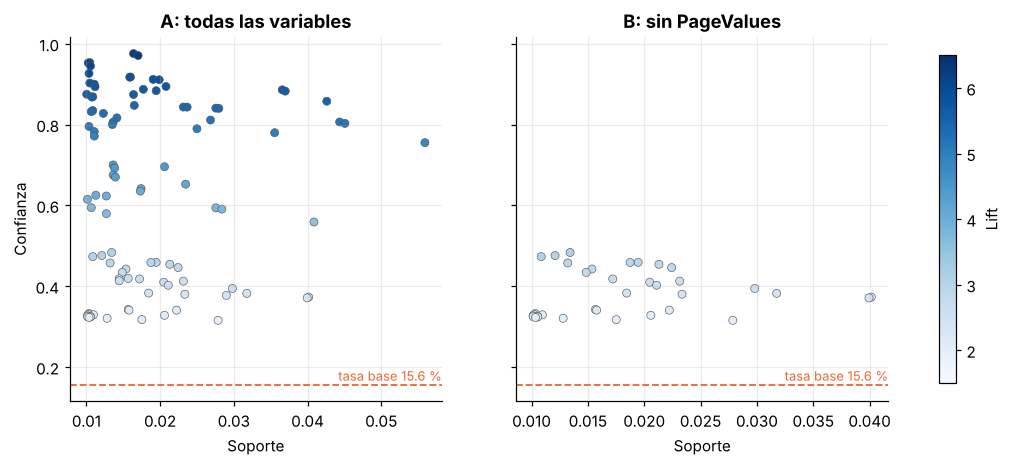

In [ ]:
# Figura 1. Soporte vs confianza (color = lift) de las reglas hacia compra
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, datos, nombre in zip(ejes, [compra_A, compra_B], ["A: todas las variables", "B: sin PageValues"]):
    sc = ax.scatter(datos.support, datos.confidence, c=datos.lift, cmap="Blues", vmin=1.5, vmax=6.5, edgecolor="#555", linewidth=.4, s=28)
    ax.axhline(T_train["Revenue=compra"].mean(), color=NARANJA, ls="--", lw=1.2)
    ax.text(ax.get_xlim()[1], T_train["Revenue=compra"].mean() + .01, " tasa base 15.6 %", color=NARANJA, ha="right", fontsize=8.5)
    ax.set_title(nombre); ax.set_xlabel("Soporte")
ejes[0].set_ylabel("Confianza")
fig.colorbar(sc, ax=ejes, label="Lift", shrink=.9)
plt.savefig("figuras/asoc_1_soporte_confianza.png", dpi=160, bbox_inches="tight"); plt.show()

Cada punto es una regla hacia compra. En el escenario A hay dos nubes: una arriba (43 reglas con confianza 0.75-0.98, todas con `PageValues`) con soporte entre 1 % y 5.6 %, y otra abajo (55 reglas con confianza 0.32-0.70). En B no hay nubes separadas: las reglas van de confianza 0.31 a 0.48 con soporte de 1 % a 4 %. En ambos hay una relación inversa típica: las reglas más confiables son más específicas y cubren menos sesiones. Todas quedan muy por encima de la tasa base (línea naranja).

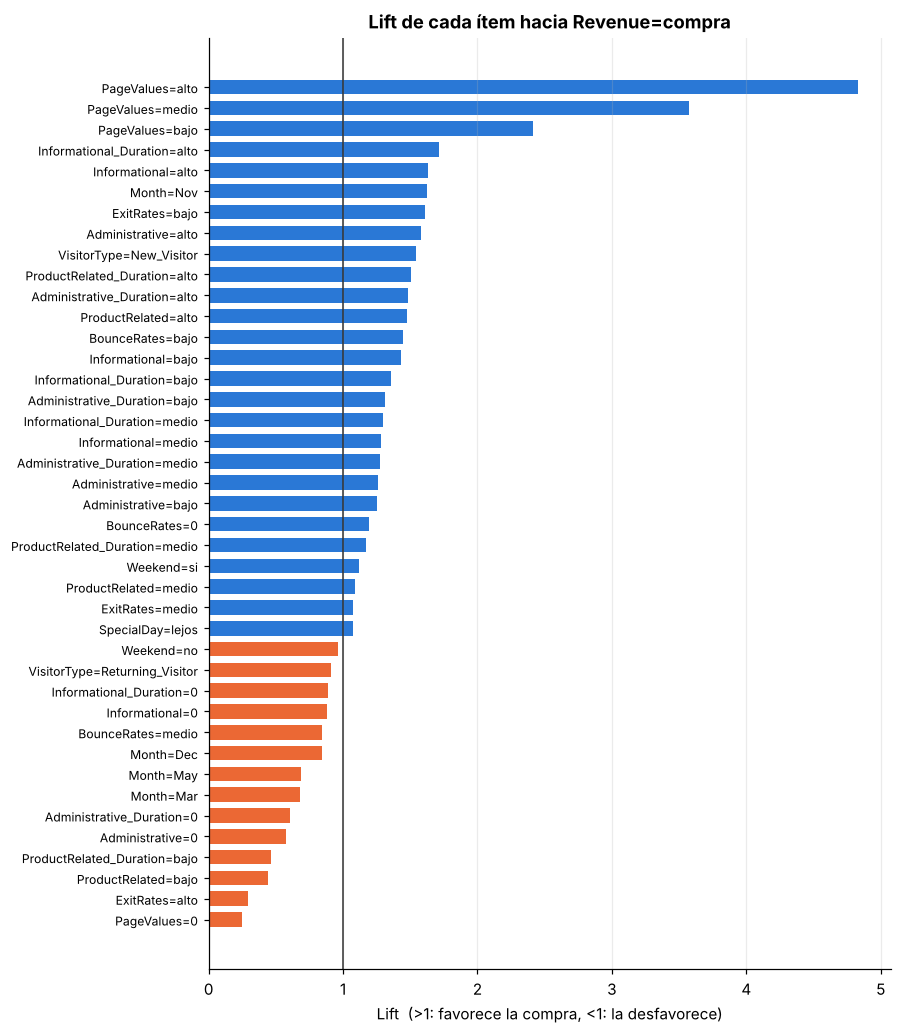

In [ ]:
# Figura 2. Efecto individual de cada ítem sobre la compra (lift de {ítem} -> compra)
orden = s.sort_values("lift")
colores = [AZUL if l > 1 else NARANJA for l in orden.lift]
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(orden.item, orden.lift, color=colores, height=.7)
ax.axvline(1, color="#333", lw=1)
ax.set_xlabel("Lift  (>1: favorece la compra, <1: la desfavorece)"); ax.set_title("Lift de cada ítem hacia Revenue=compra")
ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", alpha=0)
plt.savefig("figuras/asoc_2_lift_items.png", dpi=160, bbox_inches="tight"); plt.show()

Resume el efecto individual de cada ítem. Los de `PageValues` son los más altos; los ítems de baja actividad (`ProductRelated=bajo`, `ExitRates=alto`, `PageValues=0`) son los de menor lift.

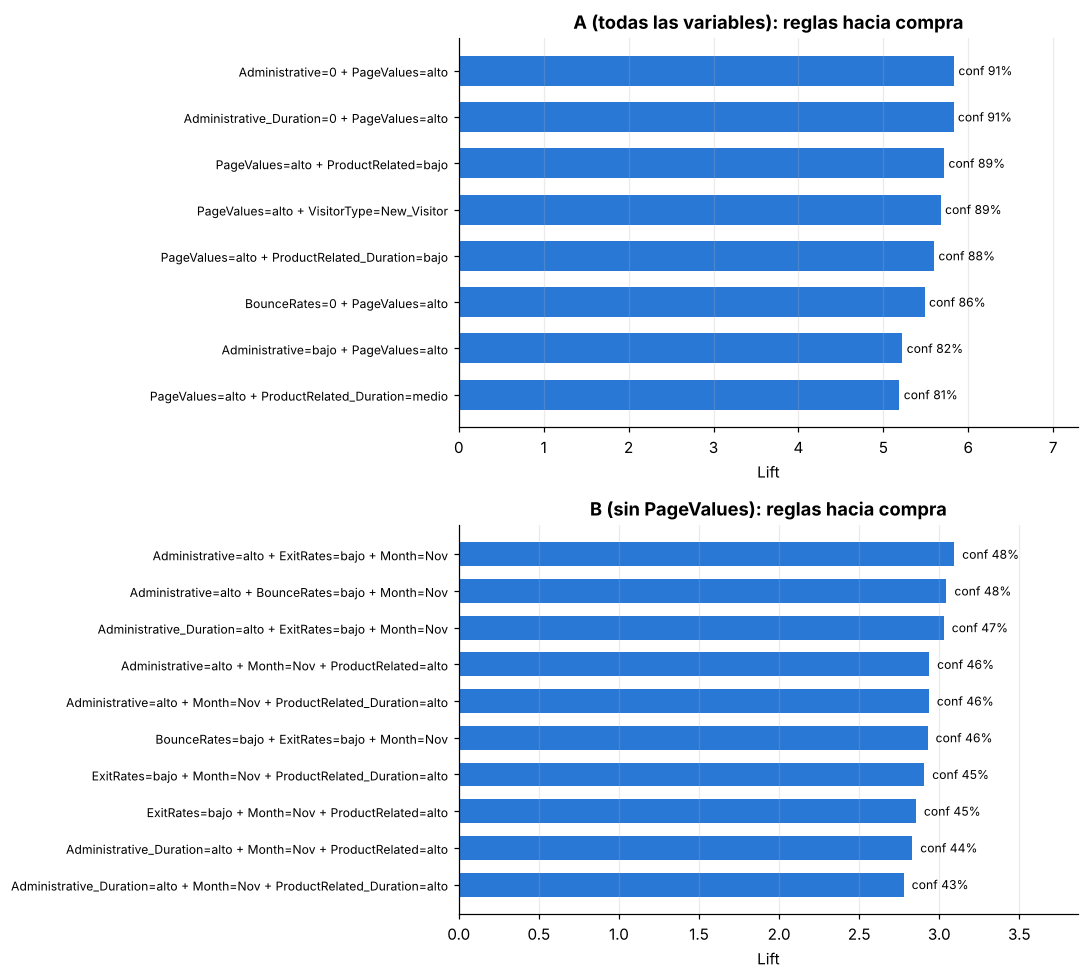

In [ ]:
# Figura 3. Mejores reglas hacia compra (top 10 por lift con al menos 2 ítems en B, y top 8 en A)
def barras(ax, datos, titulo, n):
    d = datos.head(n).iloc[::-1]
    ax.barh(d.regla, d.lift, color=AZUL, height=.65)
    for y, (l, c) in enumerate(zip(d.lift, d.confidence)):
        ax.text(l + .05, y, f"conf {c:.0%}", va="center", fontsize=8)
    ax.set_title(titulo); ax.set_xlabel("Lift"); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", alpha=0)
    ax.set_xlim(0, d.lift.max() * 1.25)
fig, ejes = plt.subplots(2, 1, figsize=(10, 9))
barras(ejes[0], compra_A[compra_A.antecedents.map(len) <= 2], "A (todas las variables): reglas hacia compra", 8)
barras(ejes[1], compra_B, "B (sin PageValues): reglas hacia compra", 10)
plt.tight_layout(); plt.savefig("figuras/asoc_3_top_reglas.png", dpi=160, bbox_inches="tight"); plt.show()

Los lifts de A son ≈ 5.2-5.8 con confianza 81-91 %; los de B son ≈ 2.8-3.1 con confianza 43-48 %, y todas incluyen `Month=Nov`.
- **Tabla de reglas con confianza ≥ 0.90.** Hay 12, todas con `PageValues=alto` y soporte entre 1 % y 2 %: son muy confiables pero cubren pocas sesiones, el patrón de "bajo soporte y alta confianza". Para interpretarlas hay que mirar también el lift (5.8-6.2) y el número de sesiones que las respaldan.

In [ ]:
# Reglas hacia compra con confianza >= 0.90 (escenario A), ordenadas por soporte
alta = compra_A[compra_A.confidence >= 0.90]
print("Reglas con confianza >= 0.90:", len(alta))
alta[["regla", "support", "confidence", "lift"]].sort_values("support", ascending=False).head(10).round(3).reset_index(drop=True)

Reglas con confianza >= 0.90: 12


,regla,support,confidence,lift
0,Administrative_Duration=0 + PageValues=alto,0.020,0.911,5.828
1,Administrative=0 + PageValues=alto,0.019,0.912,5.834
2,Administrative_Duration=0 + BounceRates=0 + PageValues=alto,0.017,0.971,6.211
3,Administrative=0 + BounceRates=0 + PageValues=alto,0.016,0.976,6.242
4,Informational_Duration=0 + PageValues=alto + VisitorType=New_Visitor,0.016,0.918,5.871
5,Informational=0 + PageValues=alto + VisitorType=New_Visitor,0.016,0.917,5.868
6,BounceRates=0 + Month=May + PageValues=alto,0.011,0.900,5.759
7,PageValues=alto + ProductRelated_Duration=medio + VisitorType=New_Visitor,0.011,0.945,6.046
8,BounceRates=0 + PageValues=alto + Weekend=si,0.010,0.903,5.776
9,Administrative_Duration=0 + ExitRates=bajo + PageValues=alto,0.010,0.953,6.099


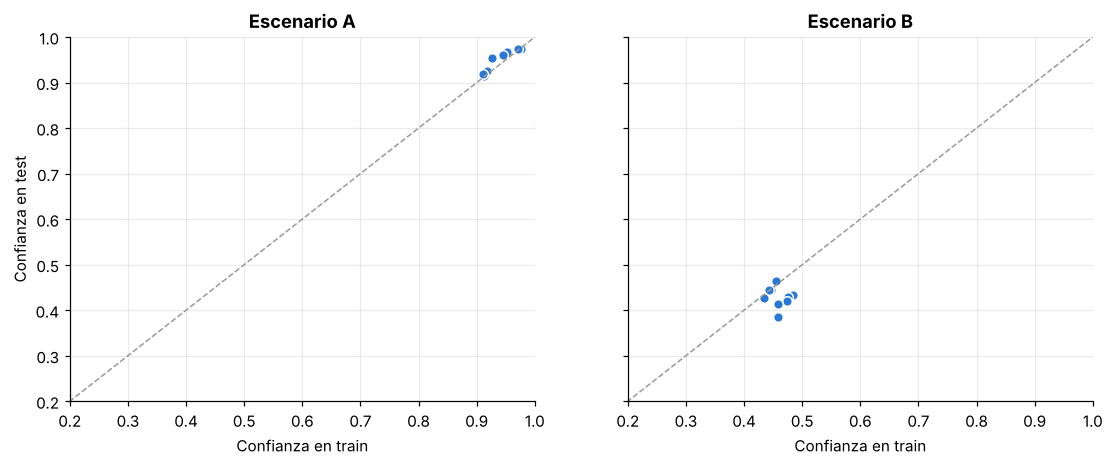

In [ ]:
# Figura 4. Estabilidad: confianza en entrenamiento vs prueba
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, v, nombre in zip(ejes, [val_A, val_B], ["A", "B"]):
    ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--")
    ax.scatter(v.conf_train, v.conf_test, color=AZUL, s=40, edgecolor="white")
    ax.set_title(f"Escenario {nombre}"); ax.set_xlabel("Confianza en train")
    ax.set_xlim(.2, 1); ax.set_ylim(.2, 1)
ejes[0].set_ylabel("Confianza en test")
plt.savefig("figuras/asoc_4_validacion.png", dpi=160, bbox_inches="tight"); plt.show()

Los puntos se agrupan sobre la diagonal, así que la confianza se mantiene fuera de la muestra de entrenamiento.

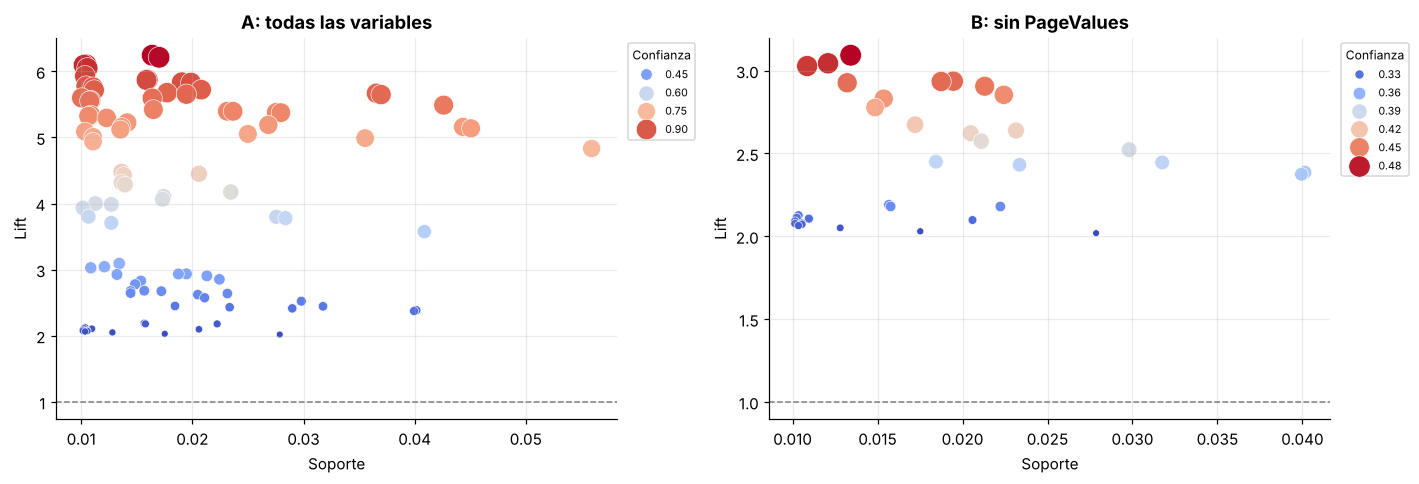

In [ ]:
# Figura 5. Soporte vs lift (color y tamaño = confianza)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, datos, nombre in zip(ejes, [compra_A, compra_B], ["A: todas las variables", "B: sin PageValues"]):
    sns.scatterplot(data=datos, x="support", y="lift", hue="confidence", size="confidence",
                    sizes=(20, 200), palette="coolwarm", ax=ax)
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.set_title(nombre); ax.set_xlabel("Soporte"); ax.set_ylabel("Lift")
    ax.legend(title="Confianza", fontsize=7, title_fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig("figuras/asoc_6_soporte_lift.png", dpi=160, bbox_inches="tight"); plt.show()

En A, las reglas de mayor confianza (puntos grandes y rojos) tienen lift de 5 a 6.2 y soporte bajo; las de lift 2-3 tienen confianza menor. En B todas están entre lift 2 y 3.1, y las de mayor lift también tienen mayor confianza. Ninguna cae cerca de la línea de lift = 1.

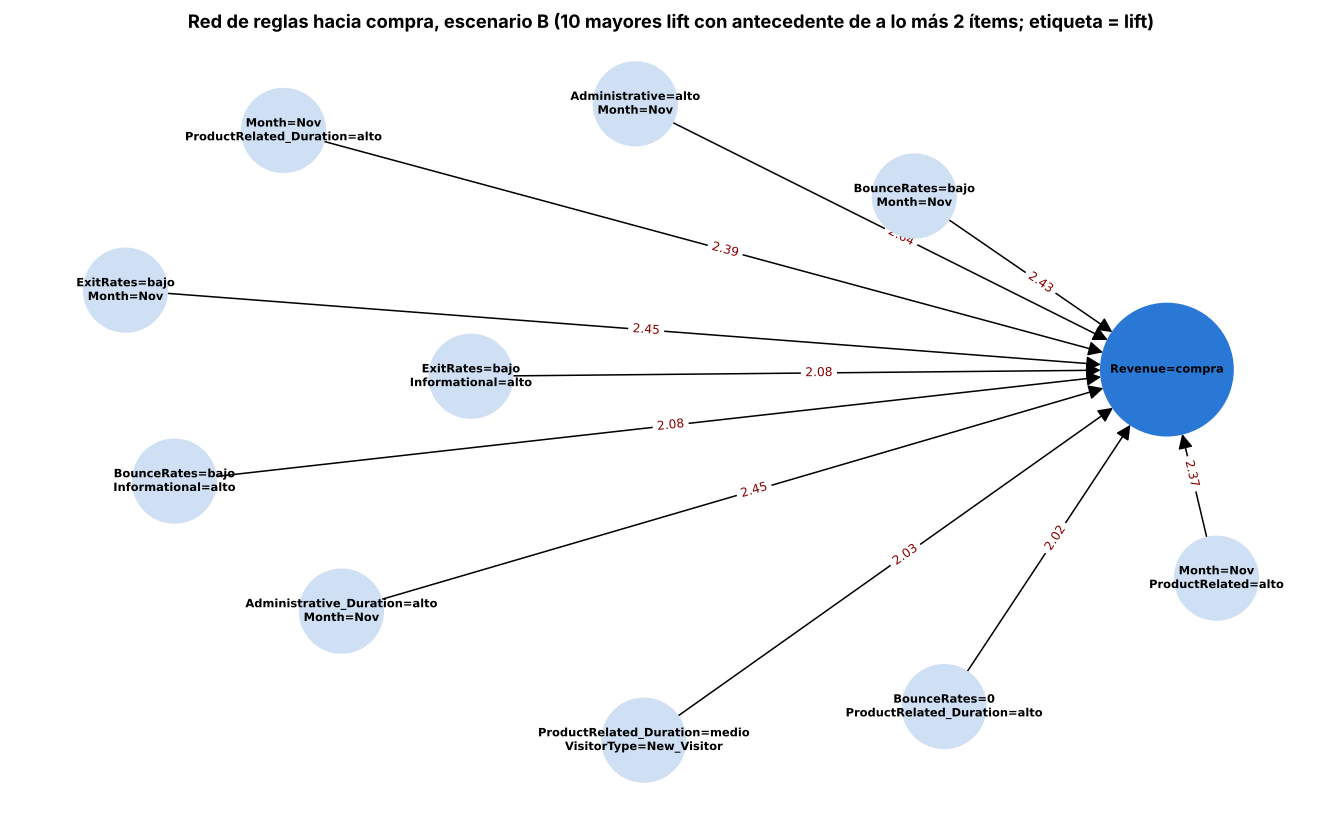

In [ ]:
# Red de reglas (top 10 por lift, antecedente de a lo más 2 ítems). Cada conjunto de ítems es un nodo.
def red_de_reglas(reglas, titulo, archivo, n=10):
    G = nx.DiGraph()
    top = reglas[reglas.antecedents.map(len) <= 2].sort_values("lift", ascending=False).head(n)
    for _, fila in top.iterrows():
        G.add_edge("\n".join(sorted(fila.antecedents)), "\n".join(sorted(fila.consequents)), weight=fila.lift)
    plt.figure(figsize=(12, 7))
    pos = nx.spring_layout(G, k=1.2, seed=42)
    colores = [AZUL if n_ == "Revenue=compra" else "#cfe0f5" for n_ in G.nodes]
    tam = [7500 if n_ == "Revenue=compra" else 3000 for n_ in G.nodes]
    nx.draw(G, pos, with_labels=True, node_size=tam, node_color=colores, font_size=7.5, font_weight="bold", arrowsize=20)
    etiquetas = {k: f"{v:.2f}" for k, v in nx.get_edge_attributes(G, "weight").items()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=etiquetas, font_color="darkred", font_size=8)
    plt.title(titulo); plt.savefig(archivo, dpi=160, bbox_inches="tight"); plt.show()

red_de_reglas(compra_B, "Red de reglas hacia compra, escenario B (10 mayores lift con antecedente de a lo más 2 ítems; etiqueta = lift)", "figuras/asoc_7_red_B.png")

Todas las flechas apuntan a `Revenue=compra`. Los antecedentes más repetidos incluyen `Month=Nov` (lift 2.37-2.64), seguidos de combinaciones de `ExitRates=bajo` o `BounceRates=bajo` con `Informational=alto` (lift 2.08). Solo se grafican reglas con antecedente de a lo más 2 ítems para que la red sea legible.

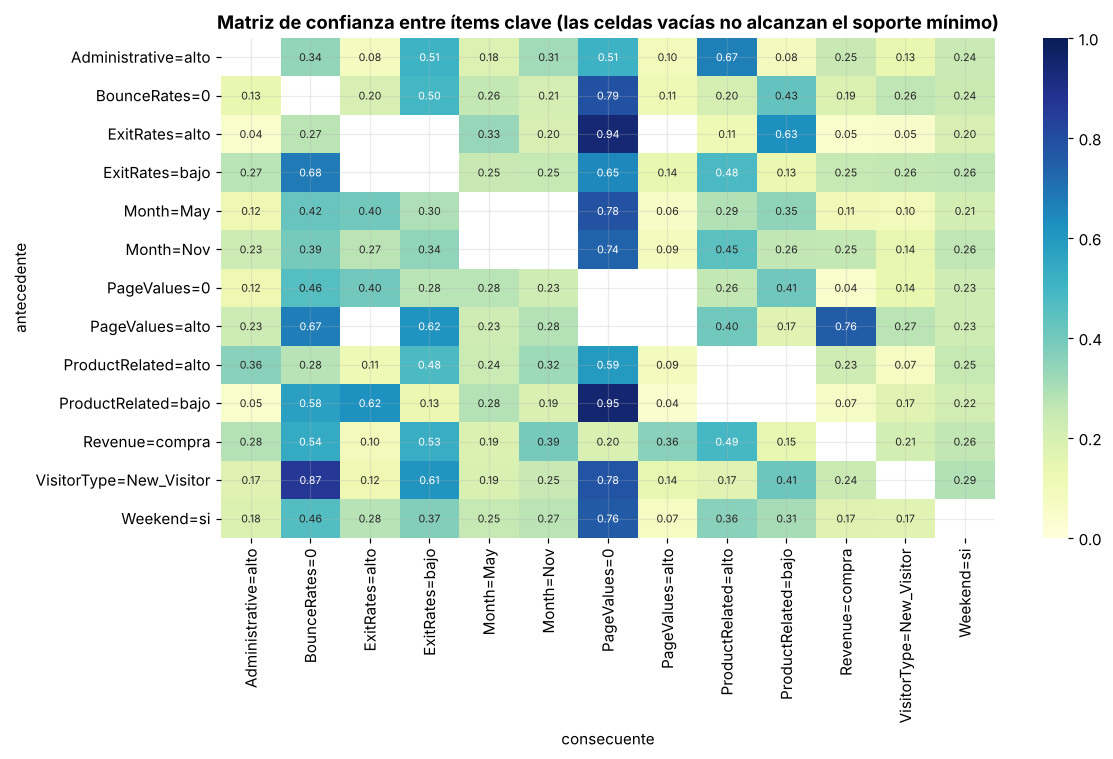

In [ ]:
# Matriz de confianza entre ítems individuales (antecedente en filas, consecuente en columnas)
simples = reglas_A[reglas_A.antecedents.map(len).eq(1) & reglas_A.consequents.map(len).eq(1)].copy()
simples["antecedente"] = simples.antecedents.map(lambda x: next(iter(x)))
simples["consecuente"] = simples.consequents.map(lambda x: next(iter(x)))
simples = simples[simples.antecedente.isin(CLAVE) & simples.consecuente.isin(CLAVE)]
pivote = simples.pivot(index="antecedente", columns="consecuente", values="confidence")
plt.figure(figsize=(11, 7))
sns.heatmap(pivote, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Matriz de confianza entre ítems clave (las celdas vacías no alcanzan el soporte mínimo)")
plt.tight_layout(); plt.savefig("figuras/asoc_8_matriz_confianza.png", dpi=160, bbox_inches="tight"); plt.show()

La confianza no es simétrica. Por ejemplo, `PageValues=alto → compra` es 0.76, pero `compra → PageValues=alto` es solo 0.36: casi todas las sesiones con páginas de alto valor compran, pero no todas las compras pasan por ellas. También destacan `ExitRates=alto → PageValues=0` (0.94) y `ProductRelated=bajo → PageValues=0` (0.95), que describen las sesiones cortas que no compran, y `New_Visitor → BounceRates=0` (0.87). Entre los compradores, el 54 % tiene `BounceRates=0`, el 53 % `ExitRates=bajo` y el 49 % `ProductRelated=alto`.

In [ ]:
# Exportar las reglas para el informe
def exportar(r, nombre):
    r.drop(columns=["antecedents", "consequents"]).to_csv(f"data/{nombre}.csv", index=False)
exportar(compra_A, "reglas_compra_A_todas")
exportar(compra_B, "reglas_compra_B_sin_pagevalues")
exportar(ab_A, "reglas_abandono_A")
exportar(ab_B, "reglas_abandono_B")
print("Reglas exportadas a data/")

Reglas exportadas a data/


## 15. Hallazgos principales

| # | Regla (escenario) | Soporte | Confianza | Lift | Interpretación |
|---|---|---|---|---|---|
| 1 | `Administrative=0 + BounceRates=0 + PageValues=alto → compra` (A) | 1.6 % | 97.6 % | 6.24 | Sesiones directas a producto, sin rebote y con páginas de alto valor casi siempre terminan en compra. |
| 2 | `PageValues=alto + VisitorType=New_Visitor → compra` (A) | ≈ 1.8 % | ≈ 89 % | ≈ 5.7 | Los visitantes nuevos que llegan a páginas de alto valor compran. |
| 3 | `Administrative=alto + ExitRates=bajo + Month=Nov → compra` (B) | 1.3 % | 48.3 % | 3.09 | En noviembre, el usuario muy comprometido compra tres veces más que el promedio. |
| 4 | `ExitRates=bajo + Month=Nov + ProductRelated=alto → compra` (B) | 2.2 % | 44.6 % | 2.85 | Más páginas de producto y baja salida en noviembre. |
| 5 | `PageValues=0 → no_compra` (A) | 74.5 % | 96.1 % | 1.14 | Sin páginas de valor, casi nunca hay compra. |
| 6 | `ExitRates=alto → no_compra` (B) | 31.7 % | 95.5 % | 1.13 | Sesiones con páginas de alta salida terminan sin compra. |

(Las cifras provienen de las tablas de las secciones 8 y 10, calculadas con `train`; las que aparecen como "≈" corresponden a la regla redondeada en la tabla correspondiente.)

**Implicaciones para el negocio.**
- Las páginas con alto `PageValues` son las que convierten: conviene dirigir el tráfico y las campañas hacia ellas.
- Noviembre es el mes de mayor conversión relativa; en ese mes tiene sentido reforzar la experiencia de los usuarios más comprometidos (por ejemplo, recordatorios o incentivos a quienes navegan mucho).
- Una tasa de salida alta es la señal más clara de abandono; mejorar el contenido o las llamadas a la acción de esas páginas puede ayudar.

## 16. Limitaciones

- **Asociación no es causalidad.** Las reglas describen coincidencias, no efectos; por ejemplo, un `PageValues` alto es en parte consecuencia de que hubo compras.
- **Circularidad de `PageValues`.** Se calcula con información posterior a la compra, por eso se incluyó el escenario B. Las reglas del escenario A son muy fuertes, pero poco útiles para anticiparse a una compra.
- **Discretización.** Los cortes por terciles dependen de los datos y fijan los límites de "bajo / medio / alto"; otros cortes podrían producir reglas ligeramente distintas. El cero de cada variable forma su propia categoría para no mezclarlo con los valores pequeños.
- **Redundancia.** Conteo y duración de una misma sección están muy relacionados; a pesar del filtro, quedan reglas casi idénticas (por ejemplo, con `Administrative=0` o `Administrative_Duration=0`).
- **Clase minoritaria y soporte bajo.** La compra es solo el 15.6 % de las sesiones, por lo que fue necesario un soporte mínimo bajo (1 %). Con miles de reglas candidatas, algunas pueden aparecer por azar; por eso se validó con `test` (cada regla cubre solo de 21 a 64 sesiones allí).
- **Datos de un solo sitio y un solo año.** Los meses no están todos representados de forma uniforme (por ejemplo, `Month=Feb` tiene muy pocas sesiones y no entra en las reglas), así que el efecto de noviembre se interpreta con cautela.

## 17. Conclusiones

1. Apriori con `min_support = 0.01` y `max_len = 4` produjo 384 reglas hacia compra con confianza ≥ 0.30 en el escenario A; tras exigir lift ≥ 2 y mejora ≥ 0.02 quedan 98 (63 de ellas con `PageValues`) en A y 35 en B.
2. La compra se asocia con (a) páginas de alto valor (`PageValues`), (b) baja tasa de salida o rebote, (c) navegación amplia y (d) el mes de noviembre. El abandono se asocia con `PageValues=0`, `ExitRates` altas y poca navegación de productos.
3. Los patrones se mantienen en el conjunto de prueba (diferencia media de confianza de 0.01 en A y 0.03 en B), por lo que son estables.
4. Sin `PageValues`, las reglas son más modestas (confianza ≈ 48 %, lift ≈ 3) pero más útiles, porque se basan en información observable durante la sesión.
5. Estas reglas deben contrastarse con las variables relevantes del clasificador (parte 3) y con los clústeres (parte 5). Si coinciden, refuerzan la conclusión; si no, conviene discutirlo en el análisis de hallazgos del informe.

*Las reglas completas se exportaron a `data/reglas_compra_A_todas.csv`, `data/reglas_compra_B_sin_pagevalues.csv`, `data/reglas_abandono_A.csv` y `data/reglas_abandono_B.csv`, y las figuras a la carpeta `figuras/`.*